In [1]:
import sys
sys.path.append("../StochAXtic/")

In [2]:
%matplotlib inline
import os
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from mpl_toolkits.mplot3d import proj3d
from matplotlib.patches import FancyArrowPatch
import seaborn as sns
sns.set(style='ticks', context='notebook', font='serif', 
        font_scale=1.5, palette='deep')
rc_params = {'backend': 'pdf',
             'axes.labelsize': 24,
             'axes.titlesize': 32,
             'font.size': 18,
             'legend.fontsize': 20,
             'xtick.labelsize': 24,
             'ytick.labelsize': 24,
            }
plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amssymb}\usepackage{mathrsfs}\usepackage{bm}", 
    "font.family": "serif"
})

# Fig. 1

In [5]:
OUT = "./Figures/"
C_L, C_S1, C_S2, C_N, C_ANG = "#0d366b", "#2a78d6", "#eb6834", "#1baf7a", "0.25"

HEAD = "-|>,head_width=0.13,head_length=0.55"          # slim filled head, used in both panels


class Arrow3D(FancyArrowPatch):
    """2D FancyArrowPatch whose end points are projected from 3D at draw time."""
    def __init__(self, p0, p1, **kw):
        super().__init__((0, 0), (0, 0), **kw)
        self._p0, self._p1 = p0, p1

    def do_3d_projection(self, renderer=None):
        (x0, x1), (y0, y1), (z0, z1) = zip(self._p0, self._p1)
        xs, ys, zs = proj3d.proj_transform((x0, x1), (y0, y1), (z0, z1), self.axes.M)
        self.set_positions((xs[0], ys[0]), (xs[1], ys[1]))
        return min(zs)

def unit(th, ph):
    return np.array([np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)])


def arc(ax, c, u, v, r, color, lw=1.2, ls="-"):
    """Arc of radius r around point c from direction u to direction v (3D)."""
    u = u / np.linalg.norm(u); v = v / np.linalg.norm(v)
    ang = np.arccos(np.clip(u @ v, -1, 1))
    w = v - (u @ v) * u; w /= np.linalg.norm(w)
    t = np.linspace(0, ang, 60)
    p = c[:, None] + r * (np.outer(u, np.cos(t)) + np.outer(w, np.sin(t)))
    ax.plot(*p, color=color, lw=lw, ls=ls)
    return c + r * (np.cos(ang / 2) * u + np.sin(ang / 2) * w)        # mid point, for the label


def arrow(ax, c, d, color, lw=1.4, label=None, off=(0, 0, 0), fs=12):
    ax.add_artist(Arrow3D(c, c + d, arrowstyle=HEAD, mutation_scale=18, color=color, lw=lw, shrinkA=0, shrinkB=0))
    if label:
        ax.text(*(c + d * 1.08 + np.array(off)), label, color=color, fontsize=fs, ha="center", va="center")


def panel_3d(ax):
    r1, r2 = 0.9, 1.4                                   # m1 > m2: heavier one closer to the centre
    # LAL convention: x points along the separation vector from m2 to m1, so m1 sits on +x
    p1, p2 = np.array([r1, 0, 0]), np.array([-r2, 0, 0])
    # orbital plane and orbit
    sq = 2.4
    ax.add_collection3d(Poly3DCollection([[(-sq, -sq, 0), (sq, -sq, 0), (sq, sq, 0), (-sq, sq, 0)]],
                                         facecolor="#cde2fb", alpha=0.25, edgecolor="none"))
    t = np.linspace(0, 2 * np.pi, 200)
    for r in (r1, r2):
        ax.plot(r * np.cos(t), r * np.sin(t), 0 * t, color="0.6", lw=0.8, ls=":")
    for d in (np.array([1.0, 0, 0]), np.array([0, 1.0, 0])):                # x (separation) and y axes
        ax.add_artist(Arrow3D(-sq * d, sq * d, arrowstyle=HEAD, mutation_scale=15, color="0.45", lw=0.9,
                              shrinkA=0, shrinkB=0))
    ax.text(sq + 0.15, 0, 0, r"$\hat x$", fontsize=9, color="0.4")
    ax.text(0, sq + 0.25, 0, r"$\hat y$", fontsize=10, color="0.4")
    ax.text(-sq + 0.2, -sq + 0.2, 0.02, "orbital plane", fontsize=9, color="#256abf")
    # bodies
    ax.scatter(*p1, s=260, color="0.15", depthshade=False)
    ax.scatter(*p2, s=150, color="0.15", depthshade=False)
    ax.text(*(p1 + [0, -0.35, -0.25]), "$m_1$", fontsize=11)
    ax.text(*(p2 + [0, -0.35, -0.25]), "$m_2$", fontsize=11)
    # orbital angular momentum
    zhat = np.array([0, 0, 1.0])
    arrow(ax, np.zeros(3), 2.2 * zhat, C_L, lw=1.8, label=r"$\hat{\mathbf{L}}=\hat z$", off=(0, 0, 0.1), fs=13)
    # spins: (body, tilt, azimuth, colour, index, length, theta-label offset, phi-arc radius, phi-label offset)
    spins = ((p1, 0.8, np.deg2rad(-45), C_S1, 1, 1.4, [0.05, 0, 0.3], 0.65, [0.12, -0.12, -0.15]),
             (p2, 0.6, np.deg2rad(160), C_S2, 2, 1.5, [-0.1, 0, 0.12], 0.45, [0.05, 0.15, 0.02]))
    for p, th, ph, col, i, a, toff, rphi, poff in spins:
        s = unit(th, ph)
        ax.plot(*np.c_[p, p + 1.6 * zhat], color="0.55", lw=0.8, ls="--")            # L direction at the BH
        arrow(ax, p, a * s, col, label=rf"$\mathbf{{S}}_{i}$", off=(0.15, 0, 0.12))
        inpl = np.array([np.cos(ph), np.sin(ph), 0.0])
        ax.plot(*np.c_[p, p + a * np.sin(th) * inpl], color=col, lw=1, ls=":")       # projection on the plane
        ax.plot(*np.c_[p + a * np.sin(th) * inpl, p + a * s], color=col, lw=0.6, ls=":")
        m = arc(ax, p, zhat, s, 0.6 * a, col)
        ax.text(*(m + toff), rf"$t_{i}$", color=col, fontsize=12)
        m = arc(ax, p, np.array([1.0, 0, 0]), inpl, rphi, col, lw=1.0)
        ax.text(*(m + poff), rf"$\phi_{i}$", color=col, fontsize=11)
    # observer
    iota, phi_o = 0.7, np.deg2rad(-60)
    n = unit(iota, phi_o)
    arrow(ax, np.zeros(3), 2.4 * n, C_N, lw=1.5, label=r"$\hat{n}$ (to observer)", off=(0.9, 0, 0.3), fs=11)
    m = arc(ax, np.zeros(3), zhat, n, 1.1, C_N)
    ax.text(*(m + [-0.05, 0, 0.18]), r"$\iota$", color=C_N, fontsize=13)
    nproj = np.array([np.cos(phi_o), np.sin(phi_o), 0.0])
    ax.plot(*np.c_[np.zeros(3), 2.4 * np.sin(iota) * nproj], color=C_N, lw=0.8, ls=":")
    ax.plot(*np.c_[2.4 * np.sin(iota) * nproj, 2.4 * n], color=C_N, lw=0.6, ls=":")
    m = arc(ax, np.zeros(3), np.array([1.0, 0, 0]), nproj, 0.75, C_N, lw=1.0)
    ax.text(*(m + [0.05, -0.32, -0.05]), r"$\phi$", color=C_N, fontsize=12)
    ax.set(xlim=(-2.4, 2.4), ylim=(-2.4, 2.4), zlim=(-0.4, 2.4))
    ax.set_box_aspect((1, 1, 0.6))
    ax.view_init(elev=20, azim=-75)
    ax.set_axis_off()


def panel_side(ax):
    a, th = 1.0, 0.95
    ax.axhline(0, color="#86b6ef", lw=6, alpha=0.4)
    ax.text(-0.95, -0.12, "orbital plane", color="#256abf", fontsize=9)
    ax.annotate("", xy=(0, 1.35), xytext=(0, 0), arrowprops=dict(arrowstyle=HEAD, mutation_scale=18, shrinkA=0, shrinkB=0, color=C_L, lw=1.4))
    ax.text(0.04, 1.38, r"$\hat{\mathbf{L}}$", color=C_L, fontsize=13)
    sx, sz = a * np.sin(th), a * np.cos(th)
    ax.annotate("", xy=(sx, sz), xytext=(0, 0), arrowprops=dict(arrowstyle=HEAD, mutation_scale=18, shrinkA=0, shrinkB=0, color=C_S1, lw=1.4))
    ax.text(sx + 0.04, sz + 0.04, r"$\mathbf{S}_i=m_i^2\,a_i\,\hat{\mathbf{s}}_i$", color=C_S1, fontsize=11)
    ax.plot([sx, sx], [0, sz], color=C_S1, lw=0.8, ls=":")
    ax.plot([0, sx], [sz, sz], color=C_S1, lw=0.8, ls=":")
    ax.annotate("", xy=(0, sz), xytext=(0, 0), arrowprops=dict(arrowstyle=HEAD, mutation_scale=18, shrinkA=0, shrinkB=0, color="#104281", lw=2))
    ax.text(-0.9, sz / 2, r"$\chi_{i,z}=a_i\cos t_i$" "\n(aligned models)", color="#104281", fontsize=10)
    ax.annotate("", xy=(sx, 0), xytext=(0, 0), arrowprops=dict(arrowstyle=HEAD, mutation_scale=18, shrinkA=0, shrinkB=0, color=C_S2, lw=1.4))
    ax.text(sx / 2 - 0.25, -0.28, r"$\chi_{i,\perp}=a_i\sin t_i$" "\n(precession)", color=C_S2, fontsize=10)
    t = np.linspace(np.pi / 2, np.pi / 2 - th, 40)
    ax.plot(0.35 * np.cos(t), 0.35 * np.sin(t), color=C_ANG, lw=1.2)
    ax.text(0.17, 0.42, r"$t_i$", fontsize=12)
    ax.set(xlim=(-1.0, 1.25), ylim=(-0.45, 1.6), aspect="equal")
    ax.set_axis_off()

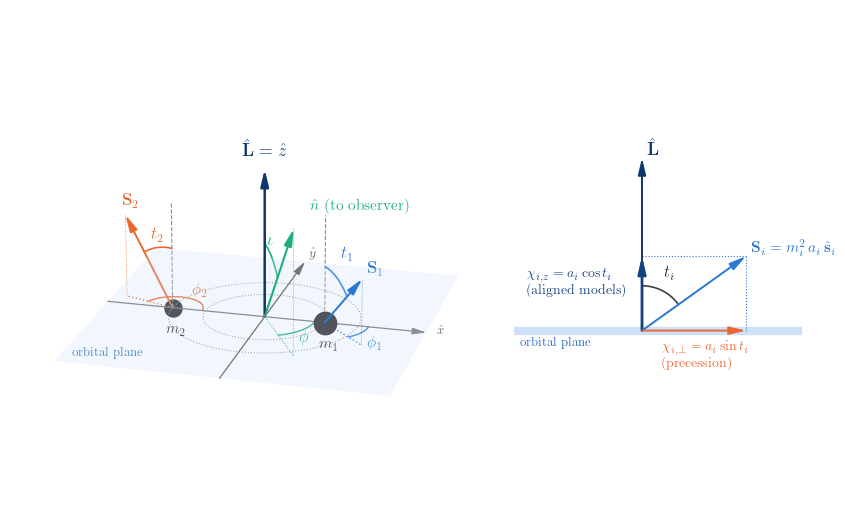

In [6]:
fig = plt.figure(figsize=(8, 5.2))
ax3 = fig.add_axes([0.0, 0.0, 0.62, 1.0], projection="3d")
panel_3d(ax3)
ax2 = fig.add_axes([0.63, 0.08, 0.36, 0.84])
panel_side(ax2)
#fig.savefig(OUT + "binary_angles.pdf", bbox_inches="tight")

# Fig. 2

In [7]:
OUT = "./Figures/"
T_SUN = 4.925490947641267e-06
Q, CHI = 0.5, 0.4                                  # aligned example: chi_1z = chi_2z = 0.4
MASSES = (20.0, 40.0)
COL = {20.0: "#2a78d6", 40.0: "#eb6834"}
X_MIN, X_REF = 4e-3, 5e-3
PREC = dict(a=0.8, theta=1.2, phi12=1.0)           # precessing example


def components(M, q=Q):
    return M / (1 + q), M * q / (1 + q)


def td_waveform(M):
    import lal, lalsimulation as ls
    m1, m2 = components(M)
    dt = 0.02 * M * T_SUN                           # same sampling in units of M
    hp, hc = ls.SimInspiralChooseTDWaveform(
        m1 * lal.MSUN_SI, m2 * lal.MSUN_SI, 0, 0, CHI, 0, 0, CHI, 100e6 * lal.PC_SI, 0.0, 0.0, 0.0, 0.0, 0.0,
        dt, X_MIN / (M * T_SUN), X_MIN / (M * T_SUN), None, ls.GetApproximantFromString("IMRPhenomXAS"))
    h = hp.data.data
    t = float(hp.epoch) + dt * np.arange(len(h))
    return t, h


def prec_spins():
    a, th, p12 = PREC["a"], PREC["theta"], PREC["phi12"]
    s1 = (a * np.sin(th), 0.0, a * np.cos(th))
    s2 = (a * np.sin(th) * np.cos(p12), a * np.sin(th) * np.sin(p12), a * np.cos(th))
    return s1, s2

/tmp/ipykernel_1200/3385395785.py:15: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal, lalsimulation as ls


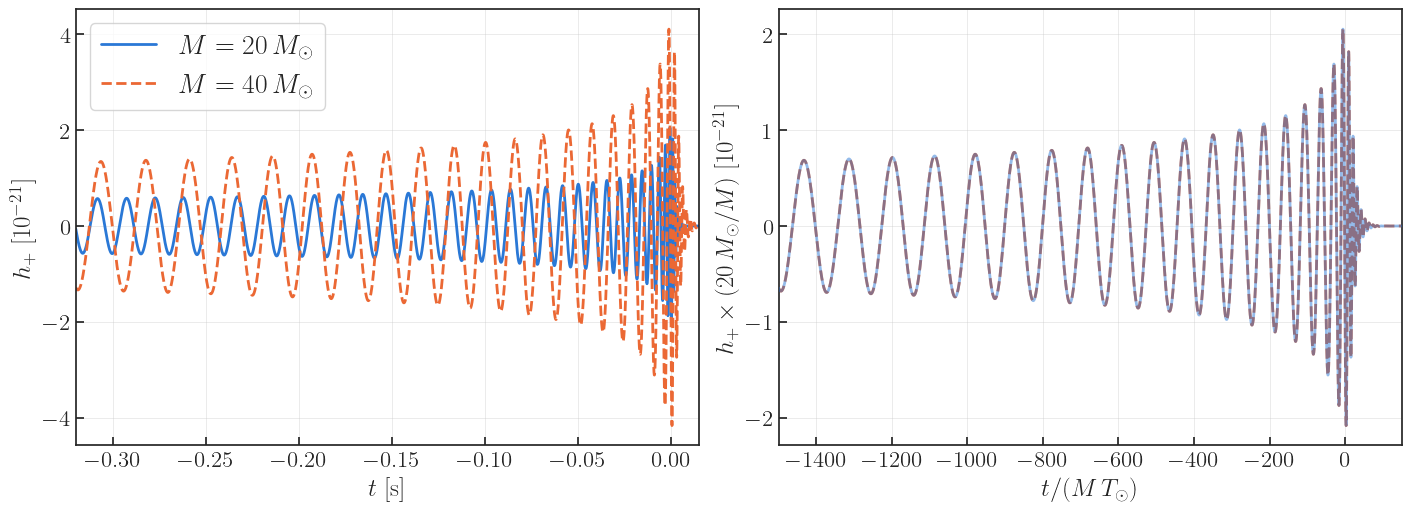

In [8]:
x = np.geomspace(1e-3, 0.3, 160)

fig = plt.figure(figsize=(14, 5), constrained_layout=True)
gs = fig.add_gridspec(1, 2)
ax_a, ax_b = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
ls = {'20.0':"-", '40.0':"--"}
for M in MASSES:
    t, h = td_waveform(M)
    lab = rf"$M={M:.0f}\,M_\odot$"
    ax_a.plot(t, h * 1e21, color=COL[M], lw=2.0, ls=ls[str(M)], label=lab)
    ax_b.plot(t / (M * T_SUN), h * 1e21 * (20.0 / M), color=COL[M], lw=2.0 if M == 20 else 2,
              alpha=1 if M == 40 else 0.5, ls=ls[str(M)], label=lab, zorder=3 if M == 20 else 2)
    f = x / (M * T_SUN)

ax_a.set(xlabel=r"$t$ [s]", ylabel=r"$h_+\ [10^{-21}]$", xlim=(-0.32, 0.015))
ax_b.set(xlabel=r"$t/(M\,T_\odot)$", ylabel=r"$h_+\times(20\,M_\odot/M)\ [10^{-21}]$", xlim=(-1500, 150))

ax_a.grid(True, which="both", alpha=0.7, lw=0.4)
ax_a.legend(fontsize=20, frameon=True, loc="upper left")
ax_a.tick_params(direction='in', which="both")

ax_b.grid(True, which="both", alpha=0.7, lw=0.4)
ax_b.tick_params(direction='in', which="both")
#fig.savefig(OUT + "scale_invariance.pdf")

# Fig. 3

In [9]:
from matplotlib.patches import Rectangle, FancyArrowPatch

OUT = "./Figures/"
FS = 9                                                              # one font size (figure at final width)
plt.rcParams.update({"text.usetex": True, "font.family": "serif", "font.size": FS,
                     "text.latex.preamble": r"\usepackage{amsmath}\usepackage{bm}"})
BLUE = ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281"]     # spins (and the plain table)
W_COL = ["#f6b26b", "#c4600f"]                                      # tides: w_1, w_{n_w}
INK, MUTED = "0.15", "0.45"
N_ROWS, H = 7, 0.36                                                 # drawn rows (ln x nodes), row height
TOP = N_ROWS * H
CAP = 0.16                                                          # height of the tide cap in (d), (e)
ARROW = dict(arrowstyle="-|>,head_width=0.12,head_length=0.35", mutation_scale=12, lw=0.9)
rng = np.random.default_rng(3)


def column(ax, x, w, color, y0=0.0, h=H, n=N_ROWS, alpha=None, spread=0.5):
    """A table column of n cells; the alpha varies from cell to cell (J values)."""
    for r in range(n):
        a = alpha if alpha is not None else 1.0 - spread + spread * rng.random()
        ax.add_patch(Rectangle((x, y0 + r * h), w, h, facecolor=color, alpha=a, edgecolor="white", lw=0.5))


def cap(ax, x, w, y, color):
    ax.add_patch(Rectangle((x, y), w, CAP, facecolor=color, edgecolor="white", lw=0.5))


def rows_axis(ax):
    ax.add_patch(FancyArrowPatch((-0.22, TOP), (-0.22, 0.0), color=MUTED, **ARROW))
    ax.text(-0.36, TOP / 2, r"$\ln x_t$", rotation=90, ha="center", va="center", color=MUTED)


def bracket(ax, x0, x1, y, label):
    ax.plot([x0, x0, x1, x1], [y, y + 0.08, y + 0.08, y], color=INK, lw=0.8)
    ax.text((x0 + x1) / 2, y + 0.13, label, ha="center", va="bottom")


def dots(ax, x, y=TOP / 2):
    ax.text(x, y, r"$\cdots$", ha="center", va="center", color=MUTED, fontsize=FS + 2)


def finish(ax, title, formula, x_right, y_top=TOP + 0.75):
    ax.text(x_right / 2, -0.4, formula, ha="center", va="top")
    ax.set_title(title, fontsize=FS + 1, pad=2)
    ax.set(xlim=(-0.5, x_right + 0.05), ylim=(-0.85, y_top))
    ax.set_axis_off()


def q_blocks(ax, draw, width, gap=0.16, dots_width=0.45, y_bracket=TOP + 0.05):
    """Draw q_1, q_2, ..., q_{n_q}; draw(x0, first) draws one block. Returns the right edge."""
    x = 0.0
    for lab in (r"$\lambda_1$", r"$\lambda_2$", None, r"$\lambda_{n_q}$"):
        if lab is None:
            dots(ax, x + dots_width / 2 - gap / 2); x += dots_width; continue
        draw(x, lab == r"$\lambda_1$")
        bracket(ax, x, x + width, y_bracket, lab)
        x += width + gap
    return x - gap


def panel_a(ax):
    w = 0.5
    def plain(x0, first):
        column(ax, x0, w, BLUE[2])
    x = q_blocks(ax, plain, w, gap=0.06, dots_width=0.6)
    rows_axis(ax)
    finish(ax, r"(a) no spins, no tides", r"$J(x_t;\,\lambda_s)$", x)


def panel_b(ax, n_s=4):
    w = 0.2
    def spins(x0, first):
        for v in range(n_s):
            column(ax, x0 + v * w, w, BLUE[1 + v])
    x = q_blocks(ax, spins, n_s * w)
    spin_key(ax, x - 1.55, TOP + 0.62, n_s)
    finish(ax, r"(b) spins", r"$J(x_t;\,\lambda_s,\,\bm\chi_{1,v},\bm\chi_{2,v})$", x, y_top=TOP + 0.8)

def tide_layout(n_k, n_w, w_col, gap_k):
    """x offsets of the tide columns (kappa major, then w) within a q block, and the block width."""
    xs, x = [], 0.0
    for c in range(n_k):
        for u in range(n_w):
            xs.append((c, u, x)); x += w_col
        x += gap_k
    return xs, x - gap_k

def spin_key(ax, x, y, n_s=3):
    """Colour key of the spin samples v (the shades of (b))."""
    for v in range(n_s):
        ax.add_patch(Rectangle((x + 0.12 * v, y - 0.06), 0.12, 0.12, facecolor=BLUE[1 + v]))
    ax.text(x + 0.12 * n_s + 0.04, y, r"$v=1,\ldots,n_\chi$", ha="left", va="center", fontsize=FS - 1)
    
def w_key(ax, x, y):
    """Colour key of the w nodes."""
    for u, lab in enumerate((r"$w_1$", r"$w_{n_w}$")):
        ax.add_patch(Rectangle((x + 0.55 * u, y - 0.06), 0.12, 0.12, facecolor=W_COL[u]))
        ax.text(x + 0.16 + 0.55 * u, y, lab, ha="left", va="center", fontsize=FS - 1)


def panel_c(ax, n_k=3, n_w=2):
    w, gk = 0.13, 0.06
    xs, width = tide_layout(n_k, n_w, w, gk)
    k_lab = [r"$\kappa_1$", r"$\kappa_2$", r"$\kappa_{n_\kappa}$"]
    def tides(x0, first):
        for c, u, dx in xs:
            column(ax, x0 + dx, w, W_COL[u], spread=0.15)
        if first:
            for c in range(n_k):
                ax.text(x0 + c * (n_w * w + gk) + n_w * w / 2, -0.04, k_lab[c], ha="center", va="top",
                        color=MUTED, fontsize=FS - 1)
    x = q_blocks(ax, tides, width)
    rows_axis(ax)
    w_key(ax, x - 1.05, TOP + 0.62)
    finish(ax, r"(c) tides", r"$J(x_t;\,\lambda_s,\,\kappa_c,\,w_u)$", x, y_top=TOP + 0.8)


def panel_d(ax, n_k=2, n_w=2, n_s=3):
    w = 0.075
    sub = n_s * w                                                       # one tide column = n_s spin columns
    gk = 0.32
    xs, width = tide_layout(n_k, n_w, sub + 0.02, gk)
    def both(x0, first):
        for c, u, dx in xs:
            cap(ax, x0 + dx, sub, TOP + 0.02, W_COL[u])
            for v in range(n_s):
                column(ax, x0 + dx + v * w, w, BLUE[1 + v])
        dots(ax, x0 + n_w * (sub + 0.02) + gk / 2 - 0.01)               # kappa nodes in between
        if first:
            for c, lab in enumerate((r"$\kappa_1$", r"$\kappa_{n_\kappa}$")):
                ax.text(x0 + xs[c * n_w][2] + n_w * (sub + 0.02) / 2, -0.04, lab, ha="center", va="top",
                        color=MUTED, fontsize=FS - 1)
    x = q_blocks(ax, both, width, gap=0.2, dots_width=0.5, y_bracket=TOP + CAP + 0.07)
    finish(ax, r"(d) tides and spins", r"$J(x_t;\,\lambda_s,\,\kappa_c,\,w_u,\,\bm\chi_{1,v},\bm\chi_{2,v})$", x,
           y_top=TOP + 0.95)


def panel_e(ax, n_k=2, n_w=2, n_s=3):
    w, h = 0.13, 0.2
    top = N_ROWS * h
    nodes = [(c, u) for c in range(n_k) for u in range(n_w)]            # tide nodes, kappa major as in (c)
    x = 0.0
    for c, u in nodes:                                                  # stage 1: tide nodes x spin samples
        cap(ax, x, n_s * w, top + 0.02, W_COL[u])
        for v in range(n_s):
            column(ax, x + v * w, w, BLUE[1 + v], h=h, alpha=0.2 + 0.8 * rng.random())
        x += n_s * w + 0.05
    x1 = x - 0.05
    ax.text(x1 / 2, top + CAP + 0.08, r"$\lambda_s$", ha="center", va="bottom")

    def arrow(xa, xb, label):
        ax.add_patch(FancyArrowPatch((xa, top / 2), (xb, top / 2), color=INK, **ARROW))
        ax.text((xa + xb) / 2, top / 2 + 0.12, label, ha="center", va="bottom")

    xa = x1 + 0.2
    arrow(xa, xa + 2.3, r"$\omega_v=p(\bm\chi_v|\bm{\Lambda}^{\rm spin})/g(\bm\chi_v)$")
    x = xa + 2.45                                                       # stage 2: one column per tide node,
    xs, width = tide_layout(n_k, n_w, w, 0.08)                          # grouped by kappa_c as in (c)
    ax.text(x + width / 2, top + 0.08, r"$\lambda_s$", ha="center", va="bottom")
    for c, u, dx in xs:
        column(ax, x + dx, w, W_COL[u], h=h, spread=0.15)
    for c in range(n_k):
        ax.text(x + xs[c * n_w][2] + n_w * w / 2, -0.04, rf"$\kappa_{c + 1}$", ha="center", va="top",
                color=MUTED, fontsize=FS - 1)
    xa = x + width + 0.2
    arrow(xa, xa + 2.3, r"$W_c(\kappa_{\rm eff}^T)\,W_u(w)$ at $(M_i,q_s)$")
    x = xa + 2.45                                                       # stage 3: one column per (q_k, M)
    column(ax, x, 0.4, BLUE[2], h=h)
    ax.text(x + 0.2, top + 0.08, r"$(M_i,q_s)$", ha="center", va="bottom")
    ax.set_title(r"(e) every call", fontsize=FS + 1, pad=2)
    ax.set(xlim=(-0.6, x + 1.0), ylim=(-0.35, top + 0.6))
    ax.set_axis_off()

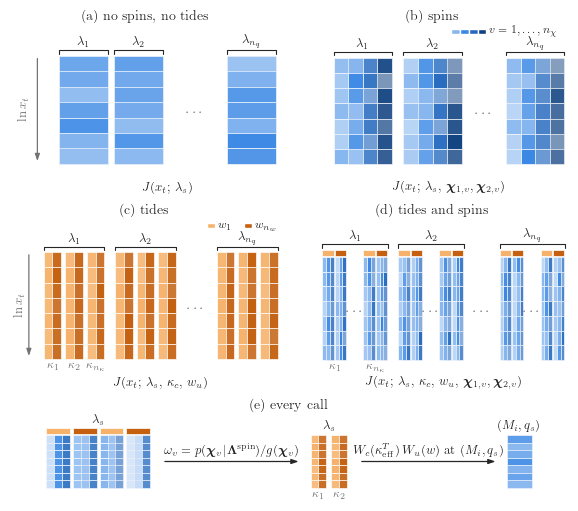

In [10]:
fig = plt.figure(figsize=(7.2, 6.2))
gs = fig.add_gridspec(3, 2, height_ratios=[1.0, 1.0, 0.5], hspace=0.12, wspace=0.06)
panel_a(fig.add_subplot(gs[0, 0])); panel_b(fig.add_subplot(gs[0, 1]))
panel_c(fig.add_subplot(gs[1, 0])); panel_d(fig.add_subplot(gs[1, 1]))
panel_e(fig.add_subplot(gs[2, :]))
#fig.savefig(OUT + "table_layout_schematic.pdf", bbox_inches="tight")

# A test showing that $x_{\rm ref}$ and $f_{\rm ref}$ don't make difference

In [9]:
data_fref_convention = np.load("./fref_convention/bp2p/fref_gwtc5.npz")

In [10]:
data_fref_convention.files

['freqs',
 'ratio',
 'sigma',
 'm1',
 'm2',
 'z',
 'omega_xref',
 'omega_fref',
 'omega_xref_sigma',
 'omega_fref_sigma',
 'chi_eff',
 'seconds']

max |deviation| = 0.068%, max |d|/sigma = 2.0


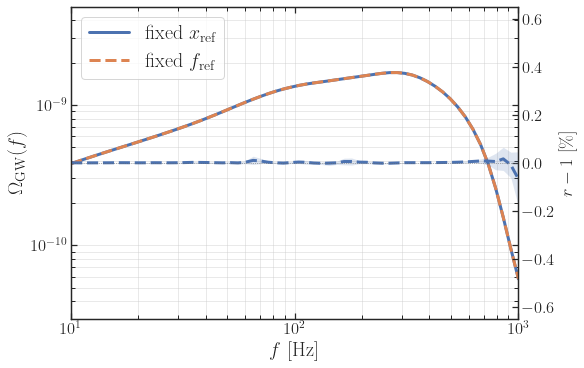

In [11]:
fig, ax = plt.subplots(figsize=(8.0, 5.0), constrained_layout=True)
ax2 = ax.twinx()
ax.grid(True, which="major", alpha=0.25, lw=0.4)

f, d, s = data_fref_convention["freqs"], 100 * (data_fref_convention["ratio"] - 1), 100 * data_fref_convention["sigma"]
ax.loglog(data_fref_convention['freqs'], data_fref_convention['omega_xref'], alpha=1, lw=3, label=r"fixed $x_\mathrm{ref}$")
ax.loglog(data_fref_convention['freqs'], data_fref_convention['omega_fref'], lw=3, ls="--", label=r"fixed $f_{\rm ref}$")
ax2.semilogx(f, d, "--", lw=3)
ax2.fill_between(f, d - 2 * s, d + 2 * s, alpha=0.18, lw=0)
print(f"max |deviation| = {np.abs(d).max():.3f}%, max |d|/sigma = {np.abs(d / s).max():.1f}")
ax2.axhline(0, color="0.4", lw=0.7, ls=":")


ax.set_ylim(2e-13, 5e-9)
ax2.set_ylim(-0.65, 0.65)
ax.set_xlabel(r"$f$ [Hz]", fontsize=20)
ax.set_ylabel(r"$\Omega_{\rm GW}(f)$", fontsize=20)
ax2.set_ylabel(r"$r-1$  [\%]")
plt.xlim(10, 1000)
ax.set_ylim(3e-11, 5e-9)
ax.legend(fontsize=20)
ax.tick_params(direction="in", which="both", top=True, right=True)
ax2.tick_params(direction="in", top=True, right=True)
ax.grid(True, which="both", linewidth=0.7, alpha=0.6)
#plt.savefig("./Figures/Comparison_convention.pdf", dpi=500, bbox_inches='tight')

# Fig.5

In [20]:
import os
import jax
jax.config.update("jax_enable_x64", True)

from stochaxtic import jax_populations as jp
from stochaxtic.fast_omega import _q_nodes, SPLIT_FRACTIONS

M_RANGE, Q_MIN, N_Q, DELTA = (1.8, 6.0), 0.3, 41, 0.005               # FastOmega BNS grid
KAPPA = np.concatenate([[0.0], np.geomspace(0.1, 3000.0, 23)])        # kappa nodes (NRTidal)
STAR = (2.7, 0.7)                                                     # (M, q) of the red star
EOS = dict(jp.TIDE_MODELS["eos_lnpoly"][1])

plt.rcParams.update({"font.size": 10, "axes.spines.top": True, "axes.spines.right": True})


def tidal_parameters(M, q):
    """kappa2T and w on (M, q) arrays, with the soft NS-mass edge of FastOmega (width delta)."""
    m1, m2 = M / (1 + q), M * q / (1 + q)
    c1, c2 = jp.kappa_eff_coefficients(q)
    lam = lambda m: np.asarray(jp.eos_lnpoly_lambda(m, EOS, DELTA))
    k1, k2 = c1 * lam(m1), c2 * lam(m2)
    kap = k1 + k2
    w = np.where(kap > 0, k1 / np.where(kap > 0, kap, 1.0), np.nan)
    return kap, w, c1 / (c1 + c2)

In [21]:
l = np.log(M_RANGE[0]) + DELTA * np.arange(int(np.ceil(np.log(M_RANGE[1] / M_RANGE[0]) / DELTA)) + 1)
lq, _ = _q_nodes("simpson", N_Q, np.log(Q_MIN))
L, LQ = np.meshgrid(l, lq, indexing="ij")
kap, w, w0 = tidal_parameters(np.exp(L), np.exp(LQ))

In [22]:
ks, ws, w0s = (float(np.ravel(v)[0]) for v in tidal_parameters(np.array(STAR[0]), np.array(STAR[1])))

red star: M = 2.7, q = 0.7: kappa2T = 94.7 (stencil [ 44.2  70.6 112.9 180.3]), w = 0.289, w/w0 = 0.382
./Figures/tide_grid.pdf


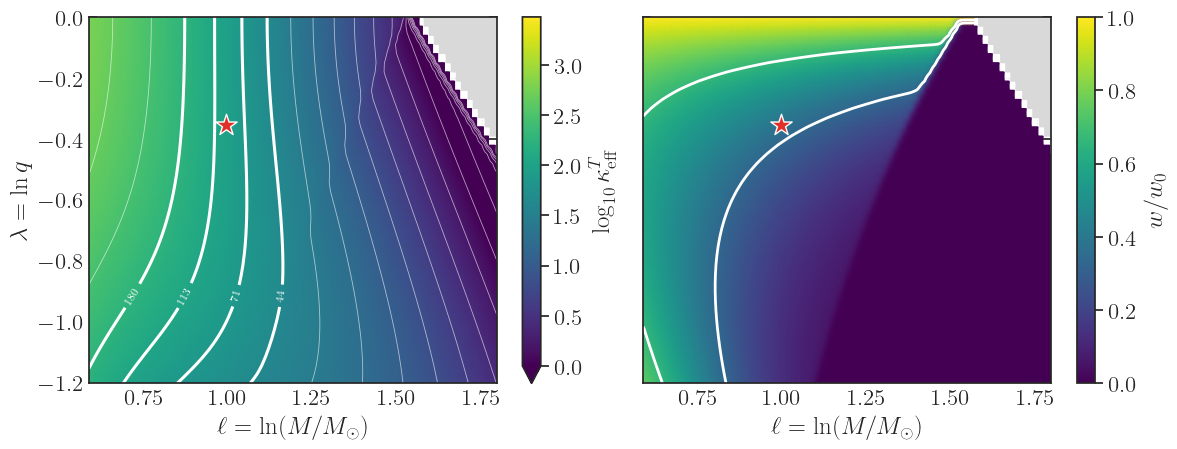

In [23]:
l = np.log(M_RANGE[0]) + DELTA * np.arange(int(np.ceil(np.log(M_RANGE[1] / M_RANGE[0]) / DELTA)) + 1)
lq, _ = _q_nodes("simpson", N_Q, np.log(Q_MIN))
L, LQ = np.meshgrid(l, lq, indexing="ij")
kap, w, w0 = tidal_parameters(np.exp(L), np.exp(LQ))
notide = kap <= 1e-6 * np.nanmax(kap)

ks, ws, w0s = (float(np.ravel(v)[0]) for v in tidal_parameters(np.array(STAR[0]), np.array(STAR[1])))
# the four kappa nodes of the cubic stencil (as in FastOmega._kappa_weights)
i0 = 1 + int(np.floor((np.log(ks) - np.log(KAPPA[1])) / np.log(KAPPA[2] / KAPPA[1])))
s = int(np.clip(i0 - 1, 1, len(KAPPA) - 4))
stencil = KAPPA[s:s + 4]
print(f"red star: M = {STAR[0]}, q = {STAR[1]}: kappa2T = {ks:.1f} (stencil {np.round(stencil, 1)}), "
      f"w = {ws:.3f}, w/w0 = {ws / w0s:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
star = dict(marker="*", s=260, color="#e0302a", edgecolor="white", linewidth=1.0, zorder=5)
grey = np.where(notide, 1.0, np.nan)

a = ax[0]
pc = a.pcolormesh(L, LQ, np.log10(np.where(notide, np.nan, np.maximum(kap, 1e-3))), cmap="viridis",
                  vmin=0.0, vmax=np.log10(3000.0), shading="gouraud", rasterized=True)
a.pcolormesh(L, LQ, grey, cmap="Greys", vmin=0, vmax=4, shading="gouraud", rasterized=True)
inside = KAPPA[(KAPPA > np.nanmin(kap[~notide])) & (KAPPA < np.nanmax(kap))]
a.contour(L, LQ, np.where(notide, np.nan, kap), levels=np.setdiff1d(inside, stencil),
          colors="white", linewidths=0.6, alpha=0.6)
cs = a.contour(L, LQ, np.where(notide, np.nan, kap), levels=stencil, colors="white", linewidths=2.2)

Mrow = np.geomspace(*M_RANGE, 4001)
krow = np.asarray(tidal_parameters(Mrow, np.full_like(Mrow, 0.4))[0])
ok = krow > 0                                   # kappa decreases with M; skip the no-tide end
pos = [(np.interp(np.log(lev), np.log(krow[ok][::-1]), np.log(Mrow[ok][::-1])), np.log(0.4))
       for lev in stencil]
a.clabel(cs, fmt=lambda v: f"{v:.0f}", fontsize=8, inline=True, manual=pos)

a.scatter(np.log(STAR[0]), np.log(STAR[1]), **star)
fig.colorbar(pc, ax=a, label=r"$\log_{10}\kappa_{\rm eff}^T$", extend="min")
a.set_xlabel(r"$\ell=\ln(M/M_\odot)$")
a.set_ylabel(r"$\lambda=\ln q$")
a.tick_params(direction="in", which="both", top=True, right=True)
a.grid(True, linestyle=":", linewidth=0.8, alpha=0.6)


b = ax[1]
pc = b.pcolormesh(L, LQ, np.where(notide, np.nan, w / w0), cmap="viridis", vmin=0, vmax=1,
                  shading="gouraud", rasterized=True)
b.pcolormesh(L, LQ, grey, cmap="Greys", vmin=0, vmax=4, shading="gouraud", rasterized=True)
b.contour(L, LQ, np.where(notide, np.nan, w / w0), levels=SPLIT_FRACTIONS[1:-1], colors="white",
          linewidths=2.0)
b.scatter(np.log(STAR[0]), np.log(STAR[1]), **star)
fig.colorbar(pc, ax=b, label=r"$w/w_0$")
b.set_xlabel(r"$\ell=\ln(M/M_\odot)$")
b.tick_params(direction="in", which="both", top=True, right=True)
b.grid(True, linestyle=":", linewidth=0.8, alpha=0.6)
fig.tight_layout()
out = "./Figures/tide_grid.pdf"
#fig.savefig(out)
print(out)

# Fig. 6

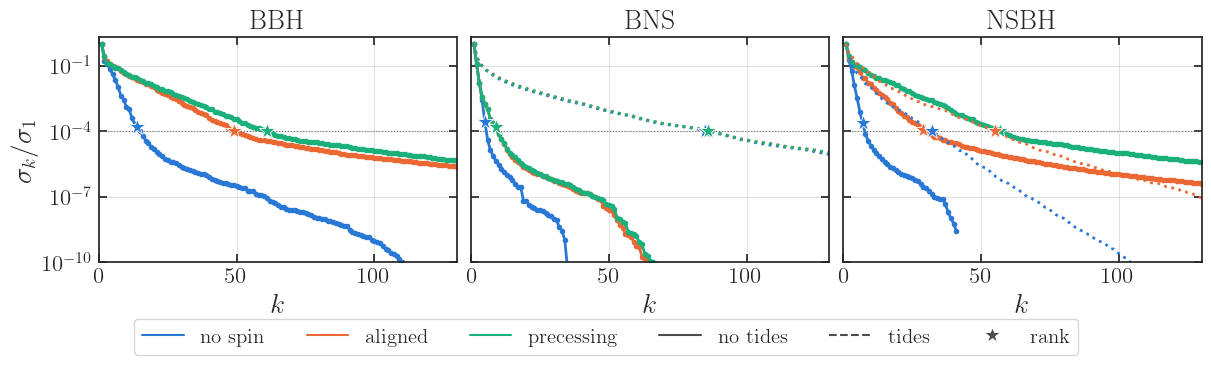

saved


In [25]:
from matplotlib.lines import Line2D          

GROUPS = {
    "BBH":  [("none", "no spin"), ("aligned", "aligned"), ("precessing", "precessing")],
    "BNS":  [("none", "no spin"), ("aligned", "aligned"), ("precessing", "precessing"),
             ("v3", "tides"), ("v3_aligned", "tides + aligned"), ("v3_precessing", "tides + precessing")],
    "NSBH": [("none", "no spin"), ("aligned", "aligned"), ("precessing", "precessing"),
             ("tides", "tides"), ("tides_aligned", "tides + aligned")],
}
COLORS = {"none": "#2a78d6", "aligned": "#eb6834", "precessing": "#1baf7a"}
TITLES = {"BBH": "BBH (IMRPhenomXPHM)", "BNS": "BNS (XP; tides: XP_NRTidalv3)",
          "NSBH": "NSBH (XAS, XPHM; tides: PhenomNSBH)"}
RANK_TOL = 1e-4

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True, constrained_layout=True)
for ax, (group, curves) in zip(axes, GROUPS.items()):
    for name, label in curves:
        path = "./SVD/" + f"sv_{group}_{name}.npz"
        if not os.path.exists(path):
            continue
        r = np.load(path)
        sv = r["sv"]
        rank = int(r["rank"])                                                     
        spin = (name.replace("tides_", "").replace("v3_", "")
                if name not in ("tides", "v3") else "none")
        ls = ":" if name.startswith(("tides", "v3")) else ".-"
        k = np.arange(1, len(sv) + 1)
        ax.semilogy(k, sv, ls, color=COLORS[spin], lw=2)                                
        ax.plot(rank, sv[rank - 1], marker="*", ms=12, color=COLORS[spin],         
                mec="white", mew=0.6, zorder=5)
    ax.axhline(RANK_TOL, color="0.4", lw=0.8, ls=":")
    ax.set(xlim=(0, 130), ylim=(1e-10, 2))
    ax.set_xlabel("$k$", fontsize=20)

    ax.tick_params(direction="in", which="both", top=True, right=True)
    ax.grid(True, linestyle="-", linewidth=0.7, alpha=0.6)
axes[0].set_ylabel(r"$\sigma_k/\sigma_1$", fontsize=20)
axes[0].set_title('BBH', fontsize=20)
axes[1].set_title('BNS', fontsize=20)
axes[2].set_title('NSBH', fontsize=20)

handles = [Line2D([], [], color=COLORS["none"], label="no spin"),
           Line2D([], [], color=COLORS["aligned"], label="aligned"),
           Line2D([], [], color=COLORS["precessing"], label="precessing"),
           Line2D([], [], color="0.3", ls="-", label="no tides"),
           Line2D([], [], color="0.3", ls="--", label="tides"),
           Line2D([], [], color="0.3", lw=0, marker="*", ms=12, mec="white", mew=0.6, label="rank")]
fig.legend(handles=handles, loc="outside lower center", ncol=6, fontsize=15, frameon=True)
plt.show()
#fig.savefig("./Figures/singular_values.pdf")
print("saved")

# Fig. 7

In [26]:
%pylab inline
test = np.load("./Convergence/sigma_detector.npz")
test.files

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


/cvmfs/software.igwn.org/conda/envs/igwn-py311/lib/python3.11/site-packages/IPython/core/magics/pylab.py:166: UserWarning: pylab import has clobbered these variables: ['i0', 'axes', 'arrow', 'f']
`%matplotlib` prevents importing * from pylab and numpy
  warn("pylab import has clobbered these variables: %s"  % clobbered +


['freqs',
 'T_seg',
 'T_obs',
 'delta_f',
 'sigma_Aplus_seg',
 'sigma_Aplus_1yr',
 'sigma_CE_seg',
 'sigma_CE_1yr']

Max(tot/sigma) 0.03770226859846325 2.423891356764907e-05
Max(tot/sigma) 0.00011664886350966691 6.071618302023473e-08
Max(tot/sigma) 0.0004470708674289213 2.2729237772379046e-07
Max(tot/sigma) 1.730001281322879e-05 1.2318682456622256e-08
Max(tot/sigma) 0.012833500241490539 6.498718088326325e-06
case         parameter     10-100 Hz  0.1-1 kHz
BBH          delta           3.3e-06    1.6e-04
BBH          table_step      3.6e-08    2.6e-08
BBH          n_q             2.9e-05    8.2e-04
BBH          rank            2.0e-06    2.4e-07
BBH          n_spin          4.2e-05    7.6e-04
BBH          seed            1.2e-04    4.5e-04
BBH          n_sub           2.5e-06    2.5e-05
BBH_nospin   n_q             2.4e-07    5.2e-06
BBH_nospin   rank            1.7e-07    6.0e-07
BNS_tides    delta           1.5e-05    1.4e-05
BNS_tides    table_step      4.3e-08    1.7e-08
BNS_tides    n_q             5.4e-05    4.3e-04
BNS_tides    rank            4.7e-06    2.6e-06
BNS_tides    n_kappa         6.3e

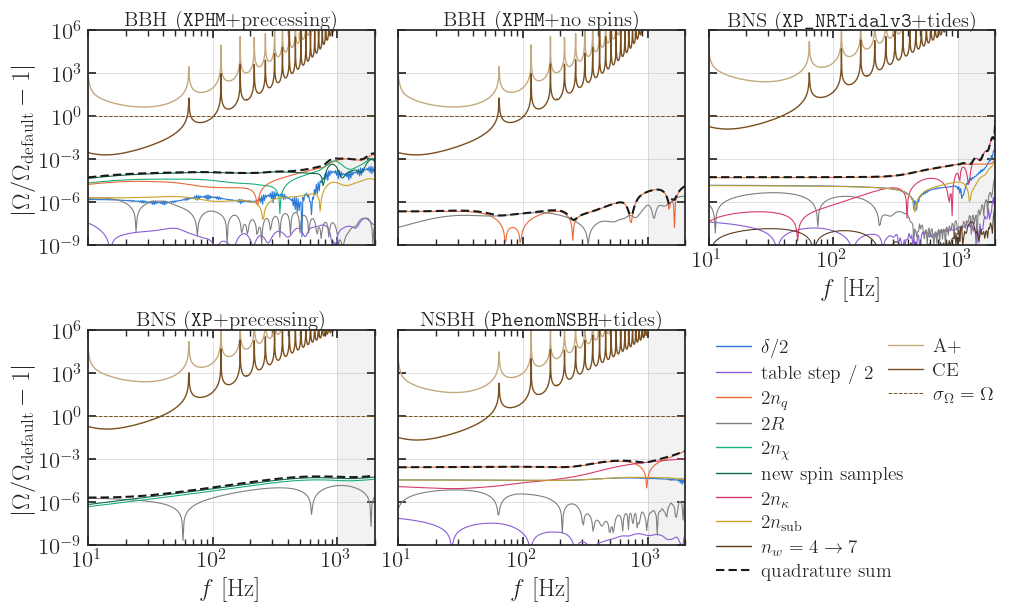

In [27]:
DATA = "./Convergence/"
CASES = {"BBH": r"BBH ($\texttt{XPHM}$+precessing)", "BBH_nospin": r"BBH ($\texttt{XPHM}$+no spins)",
         "BNS_tides": r"BNS ($\texttt{XP_NRTidalv3}$+tides)", "BNS_spin": r"BNS ($\texttt{XP}$+precessing)",
         "NSBH_tides": r"NSBH ($\texttt{PhenomNSBH}$+tides)"}
KNOBS = {"delta": r"$\delta/2$", "table_step": "table step / 2", "n_q": r"$2n_q$", "rank": r"$2R$",
         "n_spin": r"$2n_\chi$", "seed": "new spin samples", "n_kappa": r"$2n_\kappa$",
         "n_sub": r"$2n_{\rm sub}$", "n_split": r"$n_w=4\to7$"}
COLORS = dict(zip(KNOBS, ["#2a78d6", "#8a5cd6", "#eb6834", "#7f7f7f", "#1baf7a", "#0e6b48",
                          "#d63c6b", "#c9a227", "#5b3a1f"]))
DET = {"A+": ("Aplus", "#c4a97f"), "CE": ("CE", "#7a4f1e")}
BANDS = [(10.0, 100.0), (100.0, 1000.0)]
res = {c: np.load(os.path.join(DATA, f"results_{c}.npz")) for c in CASES}
det = np.load(os.path.join(DATA, "sigma_detector.npz"))
fig, axes = plt.subplots(2, 3, figsize=(10, 6), sharex=True, sharey=True, layout="constrained")
rows = []
for ax, (c, title) in zip(axes.flat, CASES.items()):
    r = res[c]
    f, base = r["freqs"], r["omega_base"]
    ax.set_title(title, pad=3, fontsize=15)
    tot = np.zeros_like(f)
    for k in KNOBS:
        if f"omega_{k}" not in r:
            continue
        d = np.abs(r[f"omega_{k}"] / base - 1)
        tot += d ** 2
        ax.loglog(f, np.maximum(d, 1e-9), color=COLORS[k], lw=0.8)
        rows.append((c, k, [d[(f >= lo) & (f <= hi)].max() for lo, hi in BANDS]))
    ax.loglog(f, np.sqrt(tot), color="k", lw=1.5, ls=(0, (4, 2)), zorder=5)
    fd = det["freqs"]
    base_d = np.interp(fd, f, base)
    for key, col in DET.values():
        ax.loglog(fd, det[f"sigma_{key}_1yr"] / base_d, color=col, lw=1.0)
    print("Max(tot/sigma)", np.max(np.sqrt(tot)/np.interp(f, det['freqs'], det["sigma_CE_1yr"] / base_d)), np.max(np.sqrt(tot)/np.interp(f, det['freqs'], det['sigma_Aplus_1yr']/base_d)))
    ax.axhline(1.0, color="#7a4f1e", lw=0.7, ls="--")
    ax.axvspan(1000, f[-1], color="0.5", alpha=0.1, lw=0)
    ax.tick_params(direction="in", which="both", top=True, right=True)
    ax.grid(True, linestyle="-", linewidth=0.7, alpha=0.6)
axes[0, 0].set(ylim=(1e-9, 1e6), xlim=(10, 2000), yticks=[1e-9, 1e-6, 1e-3, 1, 1e3, 1e6])
for ax in axes[:, 0]:
    ax.set_ylabel(r"$|\Omega/\Omega_{\rm default}-1|$")
for ax in (*axes[-1, :-1], axes[0, -1]):
    ax.set_xlabel(r"$f$ [Hz]")
axes[0, -1].tick_params(labelbottom=True)


leg_ax = axes[-1, -1]
leg_ax.axis("off")
knobs_used = [k for k in KNOBS if any(f"omega_{k}" in r for r in res.values())]
h_err = [Line2D([], [], color=COLORS[k], lw=1.0, label=KNOBS[k]) for k in knobs_used]
h_err.append(Line2D([], [], color="k", lw=1.5, ls=(0, (4, 2)), label="quadrature sum"))
h_det = [Line2D([], [], color=col, lw=1.0, label=name) for name, (_, col) in DET.items()]
h_det.append(Line2D([], [], color="#7a4f1e", lw=0.7, ls="--", label=r"$\sigma_\Omega=\Omega$"))
kw = dict(frameon=False, handlelength=1.8, handletextpad=0.5, borderaxespad=0.0, labelspacing=0.35,
          title_fontsize=18, fontsize=14)
l1 = leg_ax.legend(handles=h_err, loc="upper left", bbox_to_anchor=(0.0, 1.0),
                    **kw)
l2 = leg_ax.legend(handles=h_det, loc="upper left", bbox_to_anchor=(0.6, 1.0),
                   **kw)
leg_ax.add_artist(l1)
for leg in (l1, l2):
    leg.set_in_layout(True)
    leg._legend_box.align = "left"                     # left-aligned legend titles
#fig.savefig("./Figures/convergence.pdf")

# error budget: maximum |dOmega/Omega| over 10-100 Hz and 0.1-1 kHz
print(f"{'case':12s} {'parameter':12s} {'10-100 Hz':>10s} {'0.1-1 kHz':>10s}")
for c, k, v in rows:
    print(f"{c:12s} {k:12s} {v[0]:10.1e} {v[1]:10.1e}")

# Fig 8, 9: Comparison with PopStock

In [28]:
data_BBH = np.load("./compare_popstock_plpp_bns/results_BBH_PLPP.npz")
data_BNS = np.load("./compare_popstock_plpp_bns/results_BNS_uniform.npz")

Text(0, 0.5, '$\\Omega_\\mathrm{GW}(f)$')

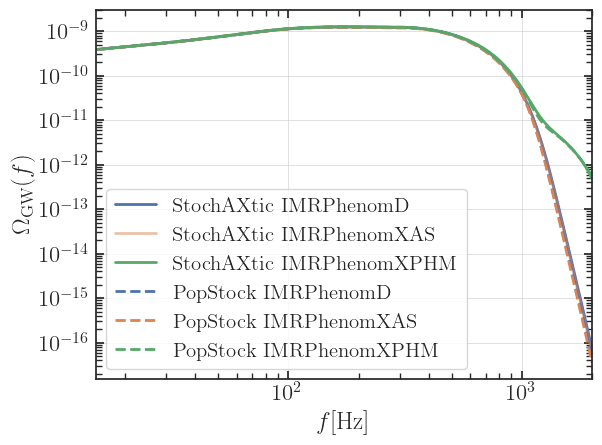

In [29]:
plt.loglog(data_BBH['freqs'], data_BBH['fast_consistent_IMRPhenomD'], color="C0", alpha=1, lw=2, label="StochAXtic IMRPhenomD")
plt.loglog(data_BBH['freqs'], data_BBH['fast_consistent_IMRPhenomXAS'], color="C1", alpha=0.5, lw=2, label="StochAXtic IMRPhenomXAS")
plt.loglog(data_BBH['freqs'], data_BBH['fast_consistent_IMRPhenomXPHM'], color="C2", alpha=1, lw=2, label="StochAXtic IMRPhenomXPHM")
plt.loglog(data_BBH['freqs'], data_BBH['pop_IMRPhenomD'], color="C0", alpha=1, ls='--', lw=2, label="PopStock IMRPhenomD")
plt.loglog(data_BBH['freqs'], data_BBH['pop_IMRPhenomXAS'], color="C1", alpha=1, ls='--', lw=2, label="PopStock IMRPhenomXAS")
plt.loglog(data_BBH['freqs'], data_BBH['pop_IMRPhenomXPHM'], color="C2", alpha=1, ls='--', lw=2, label="PopStock IMRPhenomXPHM")
plt.legend(fontsize=15)
plt.tick_params(which="both", direction="in", top=True, right=True)
plt.grid(True, which="major", linestyle="-", linewidth=0.7, alpha=0.6)
plt.xlim(15, 2000)
#plt.ylim(1e-11, 3e-9)
plt.xlabel(r"$f$[Hz]")
plt.ylabel(r"$\Omega_\mathrm{GW}(f)$")
#plt.savefig("./Figures/Omega_BBH.pdf", dpi=500, bbox_inches='tight')

Text(0, 0.5, '$\\Omega_{\\rm GW}^{\\rm StochAXtic}/\\Omega^{\\rm PopStock}_{\\rm GW}(f)-1\\,[\\%]$')

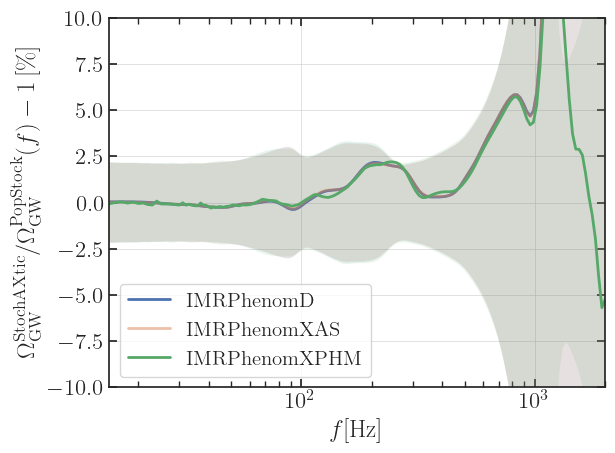

In [30]:
c = {'IMRPhenomD': "C0",'IMRPhenomXAS': "C1",'IMRPhenomXPHM': "C2"}
alpha = {'IMRPhenomD': 1,'IMRPhenomXAS': 0.5,'IMRPhenomXPHM': 1}
for waveform in ['IMRPhenomD', 'IMRPhenomXAS', 'IMRPhenomXPHM']:
    fast = data_BBH[f'fast_consistent_{waveform}']
    ps = data_BBH[f'pop_{waveform}']
    sig = data_BBH[f'popsig_{waveform}']
    freqs = data_BBH['freqs']
    rel, rs = fast / ps - 1, fast / ps * sig / ps
    plt.semilogx(freqs, 100 * rel, color=c[waveform], lw=2, alpha=alpha[waveform], label=waveform)
    plt.fill_between(freqs, -200 * rs, 200 * rs, color=c[waveform], alpha=0.12, lw=0)
    plt.xscale("log")
plt.legend(fontsize=15, loc="lower left")
plt.ylim(-10 ,10)

plt.tick_params(which="both", direction="in", top=True, right=True)
plt.grid(True, linestyle="-", linewidth=0.7, alpha=0.6)
plt.xlim(15, 2000)
plt.xlabel(r"$f$[Hz]")
plt.ylabel(r"$\Omega_{\rm GW}^{\rm StochAXtic}/\Omega^{\rm PopStock}_{\rm GW}(f)-1\,[\%]$")
#plt.savefig("./Figures/Comparison_BBH.pdf", dpi=500, bbox_inches='tight')

Text(0, 0.5, '$\\Omega_\\mathrm{GW}(f)$')

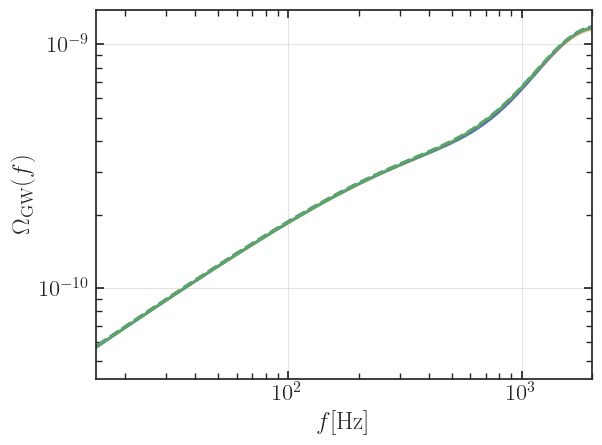

In [31]:
plt.loglog(data_BNS['freqs'], data_BNS['fast_consistent_IMRPhenomD'], color="C0", alpha=1, lw=2, label="StochAXtic IMRPhenomD")
plt.loglog(data_BNS['freqs'], data_BNS['fast_consistent_IMRPhenomXAS'], color="C1", alpha=0.5, lw=2, label="StochAXtic IMRPhenomXAS")
plt.loglog(data_BNS['freqs'], data_BNS['fast_consistent_IMRPhenomXPHM'], color="C2", alpha=1, lw=2, label="StochAXtic IMRPhenomXPHM")
plt.loglog(data_BNS['freqs'], data_BNS['pop_IMRPhenomD'], color="C0", alpha=1, ls='--', lw=2, label="PopStock IMRPhenomD")
plt.loglog(data_BNS['freqs'], data_BNS['pop_IMRPhenomXAS'], color="C1", alpha=0.5, ls='--', lw=2, label="PopStock IMRPhenomXAS")
plt.loglog(data_BNS['freqs'], data_BNS['pop_IMRPhenomXPHM'], color="C2", alpha=1, ls='--', lw=2, label="PopStock IMRPhenomXPHM")
plt.tick_params(which="both", direction="in", top=True, right=True)
plt.grid(True, linestyle="-", linewidth=0.7, alpha=0.6)
plt.xlim(15, 2000)
plt.xlabel(r"$f$[Hz]")
plt.ylabel(r"$\Omega_\mathrm{GW}(f)$")
#plt.savefig("./Figures/Omega_BNS.pdf", dpi=500, bbox_inches='tight')

Text(0, 0.5, '$\\Omega_{\\rm GW}^{\\rm StochAXtic}/\\Omega^{\\rm PopStock}_{\\rm GW}(f)-1\\,[\\%]$')

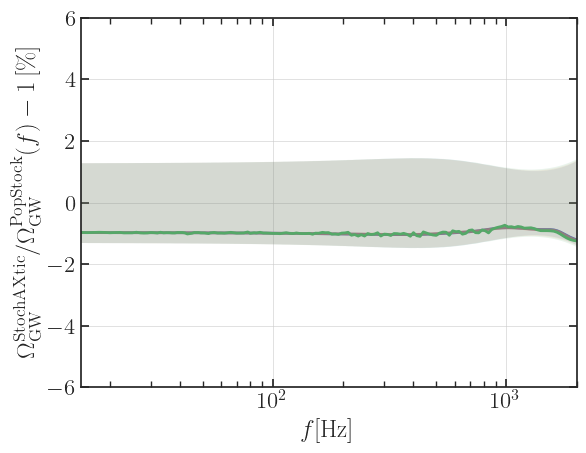

In [32]:
c = {'IMRPhenomD': "C0",'IMRPhenomXAS': "C1",'IMRPhenomXPHM': "C2"}
alpha = {'IMRPhenomD': 1,'IMRPhenomXAS': 0.5,'IMRPhenomXPHM': 1}
for waveform in ['IMRPhenomD', 'IMRPhenomXAS', 'IMRPhenomXPHM']:
    fast = data_BNS[f'fast_consistent_{waveform}']
    ps = data_BNS[f'pop_{waveform}']
    sig = data_BNS[f'popsig_{waveform}']
    freqs = data_BNS['freqs']
    rel, rs = fast / ps - 1, fast / ps * sig / ps
    plt.semilogx(freqs, 100 * rel, color=c[waveform], lw=2, alpha=alpha[waveform], label=waveform)
    plt.fill_between(freqs, -200 * rs, 200 * rs, color=c[waveform], alpha=0.12, lw=0)
    plt.xscale("log")
plt.ylim(-6 ,6)

plt.tick_params(which="both", direction="in", top=True, right=True)
plt.grid(True, linestyle="-", linewidth=0.7, alpha=0.6)
plt.xlim(15, 2000)
plt.xlabel(r"$f$[Hz]")
plt.ylabel(r"$\Omega_{\rm GW}^{\rm StochAXtic}/\Omega^{\rm PopStock}_{\rm GW}(f)-1\,[\%]$")
#plt.savefig("./Figures/Comparison_BNS.pdf", dpi=500, bbox_inches='tight')

# Fig. 10: Numpyro example

In [3]:
from stochaxtic.fast_omega import FastOmega, T_SUN, A_PRE, _next_fast_len
import jax
jax.config.update('jax_enable_x64', True)
mass, rate = "bpl_double_gaussian", "madau_dickinson"

f_obs = np.arange(10, 1000.25, 0.25)
fo_obs = FastOmega(freqs=f_obs, verbose=False)
om_obs = fo_obs.make(mass, rate) 

/home/haowen.zhong/StochAXtic/Data/../StochAXtic/stochaxtic/fast_omega.py:218: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


In [4]:
O_true = np.asarray(om_obs(None, None))

In [5]:
import time
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
                         
mass, rate = "bpl_double_gaussian", "madau_dickinson"

f_obs = np.arange(10, 1000.25, 0.25)
fo_obs = FastOmega(freqs=f_obs, verbose=False) # # BBH, no spins (chapters 01-03)
om_obs = fo_obs.make(mass, rate) 
O_true = np.asarray(om_obs(None, None))
sig = 0.1 * O_true
obs = O_true + sig * np.random.default_rng(3).standard_normal(len(f_obs))

def model(obs):
    R0 = numpyro.sample("R0", dist.Uniform(1.0, 50.0))
    alpha = numpyro.sample("alpha", dist.Uniform(0, 5.0))
    beta  = numpyro.sample("beta", dist.Uniform(0, 10.0))
    zp = numpyro.sample("zp", dist.Uniform(0.5, 5.0))
    numpyro.sample("obs", dist.Normal(om_obs(None, {"R0": R0, "zp": zp, "alpha":alpha, "beta":beta}), sig), obs=obs)

t = time.time()
mcmc = MCMC(NUTS(model), num_warmup=1000, num_samples=2000, num_chains=4, progress_bar=True)
mcmc.run(jax.random.PRNGKey(0), obs)
print(f"NUTS: {time.time() - t:.1f} s")
mcmc.print_summary()

/home/haowen.zhong/.conda/envs/Hierfit/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/tmp/ipykernel_2143/3038764002.py:23: UserWarning: There are not enough devices to run parallel chains: expected 4 but got 1. Chains will be drawn sequentially. If you are running MCMC in CPU, consider using `numpyro.set_host_device_count(4)` at the beginning of your program. You can double-check how many devices are available in your system using `jax.local_device_count()`.
  mcmc = MCMC(NUTS(model), num_warmup=1000, num_samples=2000, num_chains=4, progress_bar=True)
sample: 100%|██████████| 3000/3000 [02:13<00:00, 22.54it/s, 31 steps of size 5.40e-02. acc. prob=0.94] 


NUTS: 535.4 s

                mean       std    median      5.0%     95.0%     n_eff     r_hat
        R0     17.78      0.23     17.78     17.39     18.15   1188.33      1.00
     alpha      2.88      0.04      2.88      2.82      2.95   1101.44      1.00
      beta      6.95      0.36      6.93      6.38      7.53   1345.78      1.00
        zp      2.25      0.05      2.25      2.16      2.33   1104.97      1.00

Number of divergences: 0


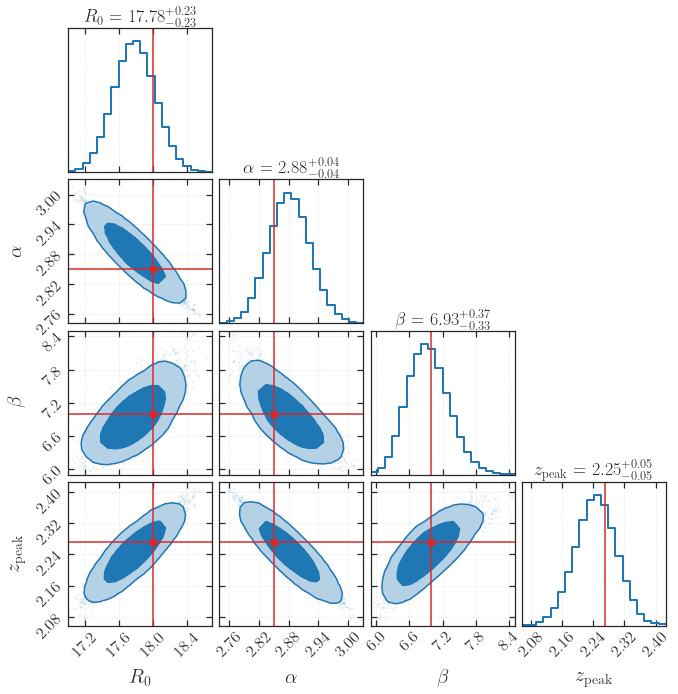

In [6]:
import corner

fig = corner.corner(
    mcmc.get_samples(),
    truths=dict(R0=17.99719280349701, alpha=2.850042173338945,
                zp=2.270700222839242, beta=6.990668900157332),
    labels=[r"$R_0$", r"$\alpha$", r"$\beta$", r"$z_{\mathrm{peak}}$"],
    label_kwargs={"fontsize": 20},
    title_kwargs={"fontsize": 18},
    truth_color="tab:red",
    truth_linestyle="--",
    color="tab:blue",
    show_titles=True,
    title_fmt=".2f",
    hist_kwargs={"linewidth": 2},  
    plot_contours=True,
    fill_contours=True,
    levels=(0.68, 0.95),
    smooth=1.0,
    smooth1d=1.0,
    max_n_ticks=5,
)

K = 4
axes = np.array(fig.axes).reshape(K, K)

for i in range(K):
    for j in range(i + 1):
        ax = axes[i, j]
        ax.tick_params(which="both", direction="in", top=True, right=True)
        ax.grid(True, linestyle=":", linewidth=0.8, alpha=0.6)
        ax.set_axisbelow(True) 
        
#plt.savefig("./Figures/MCMC_demo.pdf", dpi=500, bbox_inches='tight')

# Fig. 11, 12

In [7]:
import numpy as np
from scipy.stats import qmc


OUT = "./Figures/"
C_MC, C_QMC = "#eb6834", "#2a78d6"
REPS, MS = 64, np.arange(4, 19)                     # N = 2^4 ... 2^18
KINDS = ("indicator", "product", "additive")


def estimates(u):
    x, y = u[:, 0], u[:, 1]
    return (4 * np.mean(x ** 2 + y ** 2 <= 1),
            np.mean(8 * y / (1 + x ** 2)),
            np.mean(2 / (1 + x ** 2) + 2 / (1 + y ** 2)))

     $N$  MC(ind)  RQMC(ind)  MC(pro)  RQMC(pro)  MC(add)  RQMC(add)
    16  3.9e-01  2.0e-01  5.0e-01  4.7e-02  1.0e-01  7.5e-03
   128  1.5e-01  4.6e-02  1.9e-01  1.3e-03  3.9e-02  1.4e-04
  1024  5.1e-02  1.1e-02  6.0e-02  9.6e-05  1.2e-02  6.3e-06
  8192  1.6e-02  2.2e-03  1.9e-02  2.0e-06  5.1e-03  7.8e-07
 65536  6.6e-03  4.2e-04  8.0e-03  8.5e-09  1.8e-03  3.7e-09
slopes ($N$ >= 256): MC indicator -0.50, RQMC indicator -0.76, MC product -0.49, RQMC product -2.45, MC additive -0.50, RQMC additive -2.64


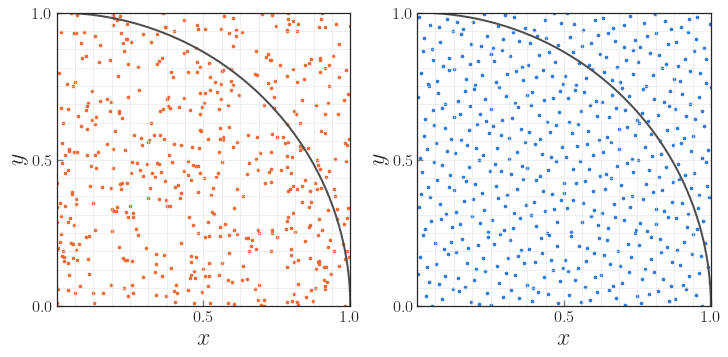

In [8]:
res = {k: np.zeros((REPS, len(MS), len(KINDS))) for k in ("MC", "RQMC")}
# Repeat REPS times
for r in range(REPS):
    sob = qmc.Sobol(2, scramble=True, bits=64, seed=np.random.default_rng([1, r])).random(2 ** MS[-1])
    rnd = np.random.default_rng([2, r]).random((2 ** MS[-1], 2))
    for j, m in enumerate(MS):
        # 2^MS points
        res["RQMC"][r, j] = estimates(sob[:2 ** m]) 
        res["MC"][r, j] = estimates(rnd[:2 ** m])
N = 2.0 ** MS
rmse = {k: np.sqrt(np.mean((v - np.pi) ** 2, axis=0)) for k, v in res.items()}     # (n_N, n_kinds)

print("     $N$  " + "  ".join(f"{s}({k[:3]})" for k in KINDS for s in ("MC", "RQMC")))
for j in range(0, len(MS), 3):
    print(f"{int(N[j]):6d}  " + "  ".join(f"{rmse[s][j, i]:.1e}" for i in range(len(KINDS)) for s in ("MC", "RQMC")))
sl = lambda e: np.polyfit(np.log(N[4:]), np.log(e[4:]), 1)[0]                    # fit N >= 256
print("slopes ($N$ >= 256): " + ", ".join(f"{s} {k} {sl(rmse[s][:, i]):+.2f}"
                                       for i, k in enumerate(KINDS) for s in ("MC", "RQMC")))

plt.rcParams.update({"font.size": 32, "axes.spines.top": True, "axes.spines.right": True})
fig = plt.figure(figsize=(10, 5), constrained_layout=True)
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1])
t = np.linspace(0, np.pi / 2, 200)
for k, (lab, u, c) in enumerate((("plain Monte Carlo", np.random.default_rng(5).random((512, 2)), C_MC),
                                 ("scrambled Sobol", qmc.Sobol(2, scramble=True, bits=64, seed=5).random(512),
                                  C_QMC))):
    a = fig.add_subplot(gs[k])
    for g in np.linspace(0, 1, 17):
        a.axvline(g, color="0.88", lw=0.5); a.axhline(g, color="0.88", lw=0.5)
    a.plot(np.cos(t), np.sin(t), color="0.3", lw=2)
    a.scatter(*u.T, s=7, color=c)
    a.set(xlim=(0, 1), ylim=(0, 1), aspect="equal", xticks=[0, 0.5, 1], yticks=[0, 0.5, 1])
    a.set_xlabel(r"$x$", fontsize=24)
    a.set_ylabel(r"$y$", fontsize=24)
    a.set_xticks([0.5, 1.0])
    a.tick_params(direction='in', which="both")
#fig.savefig(OUT + "qmc_pi_scatter.pdf")

(14.0, 786432.0)

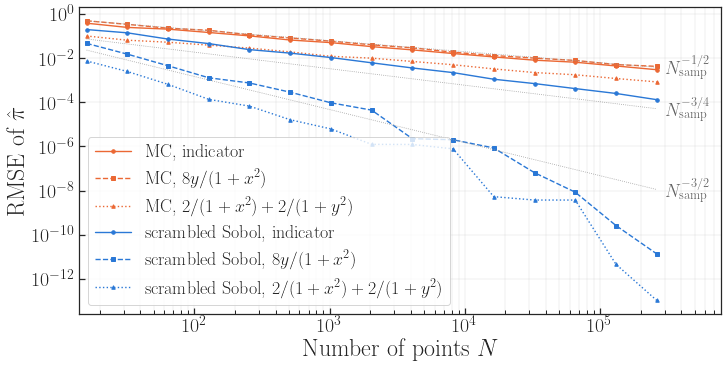

In [9]:
fig = plt.figure(figsize=(10, 5), constrained_layout=True)
style = {"indicator": ("o-", "indicator"), "product": ("s--", r"$8y/(1+x^2)$"),
         "additive": ("^:", r"$2/(1+x^2)+2/(1+y^2)$")}
for kind, c, name in (("MC", C_MC, "MC"), ("RQMC", C_QMC, "scrambled Sobol")):
    for i, k in enumerate(KINDS):
        mk, lab = style[k]
        plt.loglog(N, rmse[kind][:, i], mk, color=c, ms=3.5, lw=1.4, label=f"{name}, {lab}")
for p, y0, lab in ((-0.5, 2.0, r"$N_{\rm samp}^{-1/2}$"), (-0.75, 0.6, r"$N_{\rm samp}^{-3/4}$"), (-1.5, 1.5, r"$N_{\rm samp}^{-3/2}$")):
    plt.loglog(N, y0 * N ** p, color="0.6", lw=0.8, ls=":")
    plt.text(N[-1] * 1.15, y0 * N[-1] ** p, lab, color="0.4", fontsize=18, va="center")

plt.xlabel("Number of points $N$", fontsize=24)
plt.ylabel(r"RMSE of $\hat\pi$", fontsize=24)
plt.grid(True, which="both", alpha=0.7, lw=0.4)
plt.legend(fontsize=18, frameon=True, loc="lower left")
plt.tick_params(direction='in', which="both")
plt.xticks(fontsize=20)
plt.yticks(fontsize=20)
plt.xlim(N[0]-2, N[-1]*3)
#plt.savefig(OUT + "qmc_pi.pdf")

# Fig. 13

In [3]:
import lal
import lalsimulation as ls

from stochaxtic import jax_populations as jp

APX = ls.GetApproximantFromString("IMRPhenomXAS_NRTidalv3")
BBH = ls.GetApproximantFromString("IMRPhenomXAS")
M, KAPPA, DF = 2.7, 60.0, 0.25
ROWS = (0.7, 0.3)
N_DENSE = 41


def power(apx, m1, m2, L1, L2):
    p = lal.CreateDict()
    ls.SimInspiralWaveformParamsInsertTidalLambda1(p, L1)
    ls.SimInspiralWaveformParamsInsertTidalLambda2(p, L2)
    hp, hc = ls.SimInspiralChooseFDWaveform(m1 * lal.MSUN_SI, m2 * lal.MSUN_SI, 0, 0, 0, 0, 0, 0, 1e6 * lal.PC_SI,
                                            0., 0., 0., 0., 0., DF, 10.0, 4096.0, 20.0, p, apx)
    return np.arange(hp.data.length) * DF, np.abs(hp.data.data) ** 2 + np.abs(hc.data.data) ** 2


def fm_of(lam, q, w):
    return ls.SimNRTunedTidesMergerFrequency_v3(M, *lam(w), 1 / q, 0.0, 0.0)

def lagrange(nodes, x):
    return np.array([np.prod([(x - nodes[j]) / (nodes[i] - nodes[j]) for j in range(len(nodes)) if j != i], axis=0)
                     for i in range(len(nodes))])


def row(q):
    m1, m2 = M / (1 + q), M * q / (1 + q)
    c1, c2 = (float(np.ravel(c)[0]) for c in jp.kappa_eff_coefficients(np.array([q])))
    w0 = c1 / (c1 + c2)
    lam = lambda w: (w * KAPPA / c1, (1 - w) * KAPPA / c2)
    f, Pb = power(BBH, m1, m2, 0.0, 0.0)

    T = lambda w: power(APX, m1, m2, *lam(w))[1][:len(f)] / np.where(Pb > 0, Pb, 1.0)
    w_dense = np.linspace(0.0, w0, N_DENSE)
    Td = np.array([T(w) for w in w_dense])                                 # (N_DENSE, n_f)
    nodes4 = w0 * np.array([0, 1 / 3, 2 / 3, 1])
    T4 = np.array([T(w) for w in nodes4])
    fm = [fm_of(lam, q, w) for w in (0.0, w0)]
    fm_dense = np.array([fm_of(lam, q, w) for w in w_dense])
    band = (fm_dense.min(), 1.2 * fm_dense.max())
    cubic = lagrange(nodes4, w_dense).T @ T4                              # (N_DENSE, n_f)
    i_m = np.argmin(np.abs(f - fm[0]))
    scale = Td[0, i_m]

    err = lambda A: np.max(np.abs(A - Td), axis=0) / scale
    return dict(f=f, w0=w0, w_dense=w_dense, Td=Td, nodes4=nodes4, T4=T4, cubic=cubic, fm=fm, band=band,
                err4=err(cubic), scale=scale)

/tmp/ipykernel_31206/4112472977.py:1: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


q = 0.7: w0 = 0.755, f_merger(w=0, q^6, w0) = [1682. 1700.] Hz, shift over [0, w0] = +1.10%
q=0.7, maximum relative error: 2.1595807195327448e-05
q = 0.3: w0 = 0.979, f_merger(w=0, q^6, w0) = [869. 896.] Hz, shift over [0, w0] = +3.05%
q=0.3, maximum relative error: 0.0013637890246537899
./Figures/split_taper.pdf


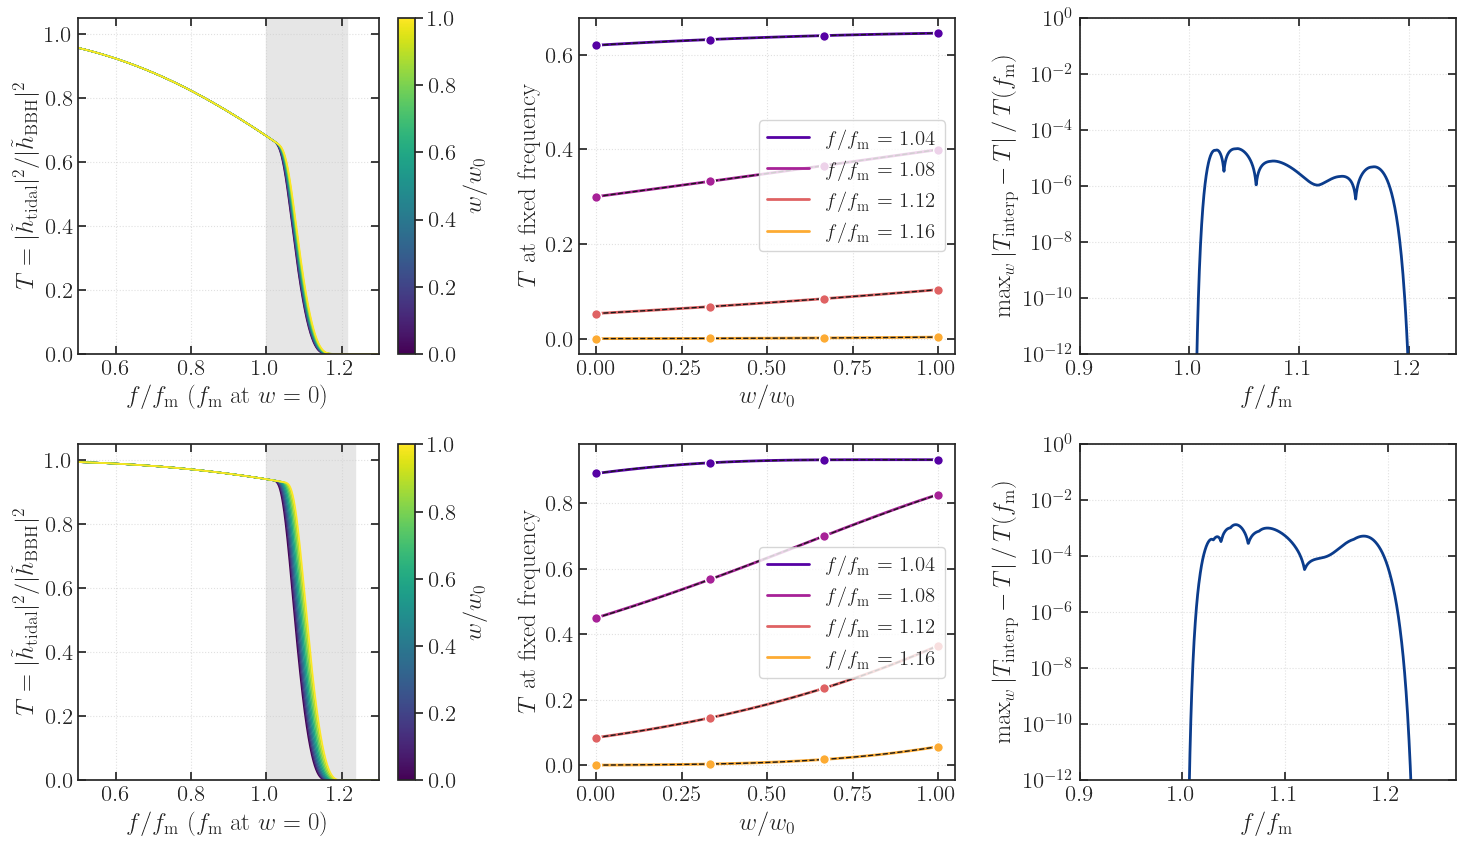

In [4]:
fig, ax = plt.subplots(len(ROWS), 3, figsize=(15, 4.4 * len(ROWS)))
cmap = plt.cm.viridis
for r, q in enumerate(ROWS):
    d = row(q)
    f, fm_ref = d["f"], d["fm"][0]
    x = f / fm_ref
    lo, hi = d["band"][0] / fm_ref, d["band"][1] / fm_ref                 # grey: tapers of all w
    print(f"q = {q}: w0 = {d['w0']:.3f}, f_merger(w=0, q^6, w0) = {np.round(d['fm'])} Hz, "
          f"shift over [0, w0] = {d['fm'][1] / d['fm'][0] - 1:+.2%}")
    # (a)
    a = ax[r, 0]
    for k, w in enumerate(d["w_dense"][::4]):
        a.plot(x, d["Td"][4 * k], color=cmap(w / d["w0"]), lw=1.2)
    a.axvspan(lo, hi, color="0.9", zorder=0)
    a.set_xlim(0.5, 1.3)
    a.set_ylim(0, None)
    a.set_xlabel(r"$f/f_{\rm m}$ ($f_{\rm m}$ at $w=0$)")
    a.set_ylabel(r"$T=|\tilde h_{\rm tidal}|^2/|\tilde h_{\rm BBH}|^2$")
    a.tick_params(direction="in", which="both", top=True, right=True)
    a.grid(True, linestyle=":", linewidth=0.8, alpha=0.6)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1))
    fig.colorbar(sm, ax=a, label=r"$w/w_0$")
    # (b)
    b = ax[r, 1]
    for k, xs in enumerate((1.04, 1.08, 1.12, 1.16)):
        i = np.argmin(np.abs(x - xs))
        col = plt.cm.plasma(0.15 + 0.22 * k)
        b.plot(d["w_dense"] / d["w0"], d["Td"][:, i], color=col, lw=2, label=f"$f/f_{{\\rm m}}$ = {xs}")
        b.plot(d["w_dense"] / d["w0"], d["cubic"][:, i], color="k", lw=1, ls="--")
        b.plot(d["nodes4"] / d["w0"], d["T4"][:, i], "o", color=col, ms=7, mec="white")
    b.set_xlabel(r"$w/w_0$")
    b.set_ylabel(r"$T$ at fixed frequency")
    b.legend(fontsize=15, frameon=True, loc="center right")
    b.tick_params(direction="in", which="both", top=True, right=True)
    b.grid(True, linestyle=":", linewidth=0.8, alpha=0.6)
    # (c)
    c = ax[r, 2]
    sel = (x > 0.9) & (x < hi + 0.03)
    c.semilogy(x[sel], np.maximum(d["err4"][sel], 1e-16), color="#0b3c8c", lw=2)
    print(f"q={q}, maximum relative error:", np.max(np.maximum(d["err4"][sel], 1e-16)))
    c.set_xlim(0.9, hi + 0.03)
    c.set_ylim(1e-12, 1)
    c.set_xlabel(r"$f/f_{\rm m}$")
    c.set_ylabel(r"$\max_w|T_{\rm interp}-T|\,/\,T(f_{\rm m})$")
    c.tick_params(direction="in", which="both", top=True, right=True)
    c.grid(True, linestyle=":", linewidth=0.8, alpha=0.6)
fig.tight_layout()
out = "./Figures/split_taper.pdf"
#fig.savefig(out)
print(out)

# Example

In [3]:
import time, numpy as np, jax, jax.numpy as jnp
import numpyro, numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
numpyro.enable_x64()
from stochaxtic.fast_omega import FastOmega

freqs = np.geomspace(5, 1024, 1000)
fo = FastOmega(freqs=freqs, m_tot_range=(6, 700))
omega = fo.make("bpl_double_gaussian", "madau_dickinson")

truth = dict(alpha_m_1=1.5754, R0=15.9)
Omega_truth = omega({"alpha_m_1": truth["alpha_m_1"]}, {"R0": truth["R0"]})
sigma = 0.01 * Omega_truth

st = time.time()
data  = Omega_truth + sigma * np.random.default_rng(1).standard_normal(len(freqs))
et = time.time()
print(f"Time elapsed：{et-st:.3f} s")

/home/haowen.zhong/.conda/envs/Hierfit/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


FastOmega: building the IMRPhenomXAS table: 121 spin/q columns x 1 tide nodes (1 kappa x 1 split), 866 frequencies each, 0.00 GB on disk ...
FastOmega: table built in 0 s, cached at /home/haowen.zhong/.cache/stochaxtic/jtable_IMRPhenomXAS_1635f0123600a4da.npy
FastOmega: SVD of 121 columns in 0 s


/home/haowen.zhong/StochAXtic/Data/../StochAXtic/stochaxtic/fast_omega.py:218: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


FastOmega: IMRPhenomXAS, spins=None, tides=False: 121 table columns, rank 8; grids lnM 953, z 444, lnq 121, lnf 1066; setup 0.4 s
Time elapsed：0.040 s


In [4]:
mS = np.random.normal(1.5754, 0.5, 4000)
rS = np.random.normal(15.9, 1.0, 4000)
omega   = fo.make("bpl_double_gaussian", "madau_dickinson")        

In [5]:
def batched_omega(m, r, batch_size=200):
    one = lambda m, r: omega({"alpha_m_1": m}, {"R0": r})   # 
    n = m.shape[0]
    mb = m.reshape(n // batch_size, batch_size)
    rb = r.reshape(n // batch_size, batch_size)
    out = jax.lax.map(lambda a: jax.vmap(one)(*a), (mb, rb)) 
    return out.reshape(n, -1)

batched = jax.jit(batched_omega, static_argnames="batch_size")
Om = batched(mS, rS)      # (4000, 400)

Text(0, 0.5, '$\\Omega_\\mathrm{GW}(f)$')

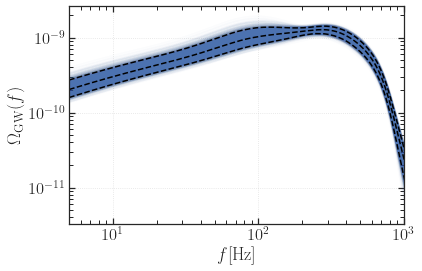

In [8]:
for i in range(2000):
    plt.loglog(fo.freqs, Om[i, :], color="C0", alpha=0.02)
plt.tick_params(which="both", direction="in", top=True, right=True)
plt.grid(True, linestyle=":", linewidth=0.8, alpha=0.6)
plt.loglog(fo.freqs, np.percentile(Om, 5, axis=0), ls="--", color="black")
plt.loglog(fo.freqs, np.percentile(Om, 50, axis=0), ls="--", color="black")
plt.loglog(fo.freqs, np.percentile(Om, 95, axis=0), ls="--", color="black")
plt.xlim(5, 1000)
plt.xlabel(r"$f$[Hz]")
plt.ylabel(r"$\Omega_\mathrm{GW}(f)$")